<div dir="rtl">

# פרויקט למידת מכונה – חלק א': איסוף, חישה ובניית סט הנתונים
**משימה:** סיווג בינארי של `RainTomorrow` – האם מחר ירדו לפחות 1.0 מ"מ משקעים.
**נתונים:** Open-Meteo Historical Weather API (ERA5 reanalysis), 6 ערים, 2010-01-01 עד 2026-10-31.

סדר המחברת עוקב אחרי מבנה הדו"ח:
1. איסוף וחישה (תוצרי `data_collection.py`, `sensing.py`)
2. הבנת הנתונים – משתנים, הסתברויות אפריוריות, איזון, קשרים, משתנים משפיעים, משתנים להסרה
3. איכות הנתונים – חוסרים, ערכים לא הגיוניים
4. הכנת הנתונים – השמטה, השלמה, דיסקרטיזציה, גזירת מאפיינים, יצירת משתנה המטרה


</div>

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import sensing
import preprocessing as pp

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titleweight": "bold"})

ROOT = Path(".").resolve()
RAW_DIR = ROOT / "data" / "raw"
PROC_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)
CITY_ORDER = ["Berlin", "London", "New York", "Sydney", "Tokyo", "Vancouver"]
PALETTE = dict(zip(CITY_ORDER, sns.color_palette("tab10", 6)))

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()

<div dir="rtl">

## 1. איסוף וחישת נתונים
`data_collection.py` שלח בקשה אחת לכל (עיר, שנה) ושמר כל תשובה כפי שהתקבלה ב-`data/raw/<city>_<year>.json`.
הלולאה סופרת בקשות **וגם את המשקל שלהן** (Open-Meteo סופר בקשה ארוכה/עם הרבה משתנים כמה קריאות), ממתינה לפני חריגה ממגבלות הדקה/השעה/היממה,
מנסה שוב ב-429/5xx ומתקנת את הבקשה ב-400. קבצים קיימים אינם מורדים שוב.

נבדוק כמה קבצים יש ונציג דוגמה של קובץ גולמי:

</div>

In [2]:
raw_files = sorted(RAW_DIR.glob("*.json"))
print(f"{len(raw_files)} raw JSON files")
sample = json.loads(raw_files[0].read_text())
print({k: v for k, v in sample.items() if k != "daily"})
pd.DataFrame(sample["daily"]).head(3)

142 raw JSON files
{'latitude': 52.54833, 'longitude': 13.407822, 'generationtime_ms': 5.931496620178223, 'utc_offset_seconds': 3600, 'timezone': 'Europe/Berlin', 'timezone_abbreviation': 'GMT+1', 'elevation': 37.0, 'daily_units': {'time': 'iso8601', 'weather_code': 'wmo code', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'temperature_2m_mean': '°C', 'apparent_temperature_mean': '°C', 'precipitation_sum': 'mm', 'rain_sum': 'mm', 'precipitation_hours': 'h', 'wind_speed_10m_max': 'km/h', 'wind_direction_10m_dominant': '°', 'snowfall_sum': 'cm', 'wind_gusts_10m_max': 'km/h', 'shortwave_radiation_sum': 'MJ/m²', 'sunshine_duration': 's', 'daylight_duration': 's', 'et0_fao_evapotranspiration': 'mm', 'relative_humidity_2m_mean': '%', 'pressure_msl_mean': 'hPa', 'cloud_cover_mean': '%', 'dew_point_2m_mean': '°C'}}


,time,weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_mean,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_direction_10m_dominant,snowfall_sum,wind_gusts_10m_max,shortwave_radiation_sum,sunshine_duration,daylight_duration,et0_fao_evapotranspiration,relative_humidity_2m_mean,pressure_msl_mean,cloud_cover_mean,dew_point_2m_mean
0,2000-01-01,71,2.8,-0.3,0.8,-2.6,2.5,1.9,9.0,12.5,197,0.42,24.8,1.33,0.0,27864.27,0.15,96,1022.6,98,0.2
1,2000-01-02,3,4.4,2.6,3.2,-0.5,0.0,0.0,0.0,16.2,261,0.00,32.8,1.42,0.0,27936.48,0.21,94,1025.9,100,2.4
2,2000-01-03,3,6.3,4.4,5.4,1.3,0.0,0.0,0.0,20.0,237,0.00,37.8,1.25,0.0,28015.53,0.48,87,1022.2,100,3.4


In [3]:
sensed = sensing.build_sensed()
sensed.to_csv(RAW_DIR / "sensed_data.csv", index=False)
summary = sensed.groupby("location").agg(rows=("date", "size"), first=("date", "min"), last=("date", "max"))
summary

rows read: 36,888 | duplicates removed: 0 | rows: 36,888


,rows,first,last
location,,,
Berlin,6148,2010-01-01,2026-10-31
London,6148,2010-01-01,2026-10-31
New York,6148,2010-01-01,2026-10-31
Sydney,6148,2010-01-01,2026-10-31
Tokyo,6148,2010-01-01,2026-10-31
Vancouver,6148,2010-01-01,2026-10-31


<div dir="rtl">

**מה התקבל:** טבלה אחת שבה כל שורה = (עיר, יום). העמודות `location` ו-`date` נוספו, וכפילויות לפי הצירוף הוסרו.
לכל העיירות אותו טווח תאריכים – כלומר לכל עיר משקל דומה בדאטה (אין עיר "דומיננטית").

</div>

<div dir="rtl">

## 2. הבנת הנתונים
### 2.1 מקור הנתונים ומשמעותם
* **Open-Meteo Historical Weather API** מבוסס בעיקר על **ERA5** של ECMWF – *reanalysis*: מודל מטאורולוגי פיזיקלי שמטמיע (data assimilation) מדידות אמיתיות
  מתחנות, לוויינים, בלונים, מטוסים ומצופים, ומפיק שחזור עקבי של מזג האוויר על גריד של כ-0.25° (~25 ק"מ), שעה-שעה, מ-1940.
* המשתנים היומיים הם **אגרגציה של ערכים שעתיים** לפי אזור הזמן המקומי (`timezone=auto`) – למשל `precipitation_sum` = סכום 24 השעות של היום המקומי.
* לכן אלו **לא מדידה ישירה של תחנה** אלא אומדן מודל לתא גריד: הם חלקים ועקביים (כמעט ללא חוסרים), אך עלולים לסטות ממדידה נקודתית (למשל הטיית "טפטוף" ידועה ב-ERA5 – יותר מדי ימים עם מעט משקעים).

</div>

In [4]:
units = sample["daily_units"]
used = [c for c in sensed.columns if c in units]
pd.DataFrame({"variable": used, "unit": [units[c] for c in used],
              "dtype": [str(sensed[c].dtype) for c in used],
              "n_unique": [sensed[c].nunique() for c in used]})

,variable,unit,dtype,n_unique
0,weather_code,wmo code,int64,13
1,temperature_2m_max,°C,float64,505
2,temperature_2m_min,°C,float64,469
3,temperature_2m_mean,°C,float64,468
4,apparent_temperature_mean,°C,float64,567
5,precipitation_sum,mm,float64,595
6,rain_sum,mm,float64,587
7,precipitation_hours,h,float64,25
8,wind_speed_10m_max,km/h,float64,547
9,wind_direction_10m_dominant,°,int64,361


<div dir="rtl">

| משתנה | משמעות | סוג |
|---|---|---|
| `location` | העיר (6 ערים) | קטגוריאלי לא ניתן לסידור |
| `date` | תאריך מקומי | זמן (ממנו נגזרת עונתיות) |
| `weather_code` | קוד WMO של מזג האוויר **החמור ביותר** ביום (0 בהיר … 99 סופת רעמים) | קטגוריאלי (המספר הוא קוד, לא כמות) |
| `temperature_2m_max/min/mean` | טמפ' מקס'/מינ'/ממוצעת בגובה 2 מ' (°C) | רציף |
| `apparent_temperature_mean` | טמפ' מורגשת ממוצעת – משלבת טמפ', לחות, רוח וקרינה (°C) | רציף |
| `precipitation_sum` | סך משקעים (גשם+שלג כמים) (mm) | רציף (אפס-מנופח) |
| `rain_sum` | משקעים בצורת גשם בלבד (mm) | רציף |
| `precipitation_hours` | מס' שעות עם משקעים ≥0.1 מ"מ (h) | בדיד 0–24 (נתייחס כרציף) |
| `wind_speed_10m_max` | מהירות רוח מקס' בגובה 10 מ' (km/h) | רציף |
| `wind_direction_10m_dominant` | כיוון רוח דומיננטי (° , 0=צפון) | רציף **מעגלי** (0°=360°) |
| `relative_humidity_2m_mean`* | לחות יחסית ממוצעת (%) | רציף |
| `pressure_msl_mean`* | לחץ מתוקנן לגובה פני הים (hPa) | רציף |
| `cloud_cover_mean`* | כיסוי עננים ממוצע (%) | רציף |
| `dew_point_2m_mean`* | נקודת טל ממוצעת (°C) | רציף |
| **`RainTomorrow`** | **משתנה המטרה**: 1 אם `precipitation_sum` של מחר ≥ 1.0 מ"מ, אחרת 0 | בינארי |

\* משתנים נוספים שאספנו מעבר ל-10 החובה – לצורכי חקירה בלבד (ראו סעיף 2.6).

</div>

<div dir="rtl">

### 2.2 יצירת משתנה המטרה (לצורך הניתוח)
בתוך כל עיר, אחרי מיון לפי תאריך: `RainTomorrow(d) = 1[precipitation_sum(d+1) ≥ 1.0]`. היום האחרון בכל עיר (אין "מחר") מקבל NaN ויוסר.

</div>

In [5]:
eda = pp.add_target(sensed.assign(date=pd.to_datetime(sensed["date"])))
eda = eda[eda[pp.TARGET].notna()].copy()
eda[pp.TARGET] = eda[pp.TARGET].astype(int)
eda["RainToday"] = (eda["precipitation_sum"] >= 1.0).astype(int)
eda["month"] = eda["date"].dt.month
print(eda.shape)

(36882, 19)


<div dir="rtl">

### 2.3 הסתברויות אפריוריות
#### משתנה המטרה

</div>

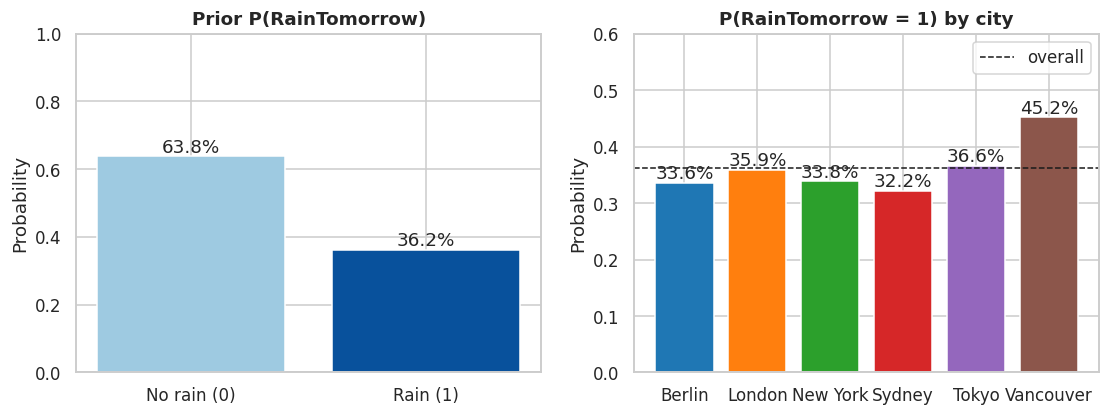

{0: 0.6377, 1: 0.3623}


In [6]:
prior = eda[pp.TARGET].value_counts(normalize=True).sort_index()
by_city = eda.groupby("location")[pp.TARGET].mean().reindex(CITY_ORDER)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bars = ax[0].bar(["No rain (0)", "Rain (1)"], prior.values, color=["#9ecae1", "#08519c"])
ax[0].bar_label(bars, labels=[f"{v:.1%}" for v in prior.values])
ax[0].set(title="Prior P(RainTomorrow)", ylabel="Probability", ylim=(0, 1))
b2 = ax[1].bar(by_city.index, by_city.values, color=[PALETTE[c] for c in by_city.index])
ax[1].bar_label(b2, labels=[f"{v:.1%}" for v in by_city.values])
ax[1].axhline(prior[1], ls="--", c="k", lw=1, label="overall")
ax[1].set(title="P(RainTomorrow = 1) by city", ylabel="Probability", ylim=(0, 0.6))
ax[1].legend()
save(fig, "01_target_prior")
print(prior.round(4).to_dict())

<div dir="rtl">

**מה למדנו:** כ-36% מהימים הם ימים שלפני גשם (RainTomorrow=1) – חוסר איזון מתון. השיעור נע בין ~32% (Sydney) ל-~45% (Vancouver), כלומר `location` לבדו כבר אינפורמטיבי. **השלכה:** בחלק ב' – מדד F1/Recall ולא רק Accuracy, ו-`location` כמאפיין.

</div>

<div dir="rtl">

#### שלושה (ויותר) משתנים רציפים – פונקציות צפיפות

</div>

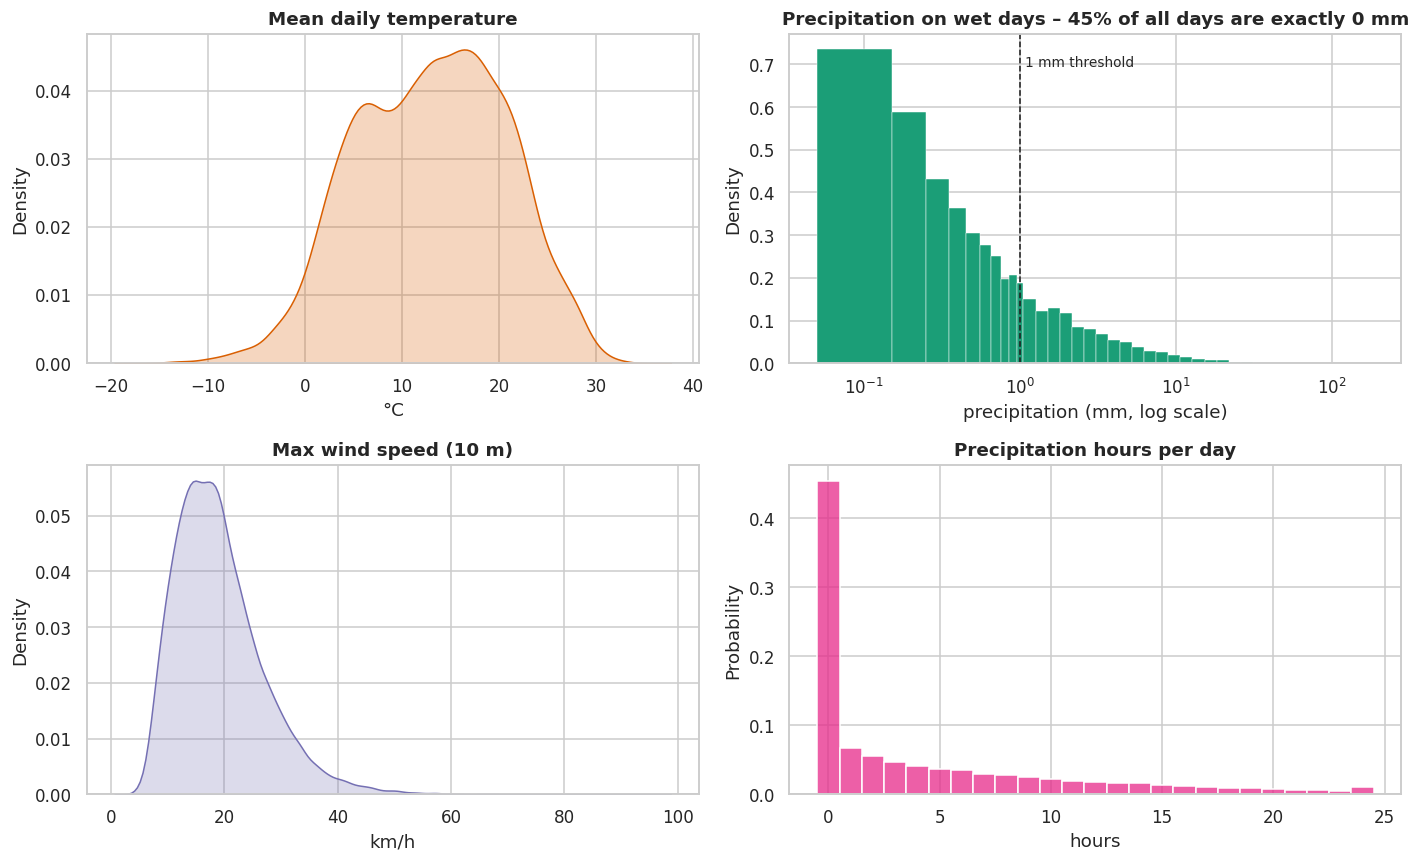

,count,mean,std,min,25%,50%,75%,max
temperature_2m_mean,36882.0,12.99,7.73,-16.8,7.0,13.3,18.8,34.9
precipitation_sum,36882.0,3.19,7.69,0.0,0.0,0.2,2.7,183.6
wind_speed_10m_max,36882.0,19.07,7.89,3.5,13.4,17.8,23.2,95.9
precipitation_hours,36882.0,4.31,6.00,0.0,0.0,1.0,7.0,24.0


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
ax = axes.ravel()
sns.kdeplot(data=eda, x="temperature_2m_mean", fill=True, ax=ax[0], color="#d95f02")
ax[0].set(title="Mean daily temperature", xlabel="°C", ylabel="Density")

pos = eda.loc[eda["precipitation_sum"] > 0, "precipitation_sum"]
# values are rounded to 0.1 mm -> bins centred on the 0.1 mm steps at the low end, log-spaced above 1 mm
edges = np.r_[np.arange(0.05, 1.0, 0.1), np.logspace(np.log10(1.05), np.log10(pos.max() + 1), 30)]
ax[1].hist(pos, bins=edges, density=True, color="#1b9e77", edgecolor="white", linewidth=0.3)
ax[1].set_xscale("log")
ax[1].set(title=f"Precipitation on wet days – {(eda['precipitation_sum']==0).mean():.0%} of all days are exactly 0 mm",
          xlabel="precipitation (mm, log scale)", ylabel="Density")
ax[1].axvline(1.0, c="k", ls="--", lw=1); ax[1].text(1.08, ax[1].get_ylim()[1]*0.9, "1 mm threshold", fontsize=9)

sns.kdeplot(data=eda, x="wind_speed_10m_max", fill=True, ax=ax[2], color="#7570b3")
ax[2].set(title="Max wind speed (10 m)", xlabel="km/h", ylabel="Density")

sns.histplot(eda["precipitation_hours"], bins=25, discrete=True, stat="probability", ax=ax[3], color="#e7298a")
ax[3].set(title="Precipitation hours per day", xlabel="hours", ylabel="Probability")
fig.tight_layout()
save(fig, "02_continuous_priors")
eda[["temperature_2m_mean", "precipitation_sum", "wind_speed_10m_max", "precipitation_hours"]].describe().T.round(2)

<div dir="rtl">

**מה למדנו:** הטמפרטורה רחבה ולא-פעמונית (איחוד 6 ערים × כל העונות). המשקעים **אפס-מנופחים** (~45% מהימים בדיוק 0) ומוטים מאוד – בציר לוגריתמי רוב הימים הרטובים בין 0.1–10 מ"מ, וסף ה-1 מ"מ חוצה אותם. הרוח מוטה ימינה עם זנב של ימי סערה. **השלכה:** דיסקרטיזציה של המשקעים (סעיף 4.1) ושימוש בסף rain_today.

</div>

<div dir="rtl">

#### שני משתנים קטגוריאליים – גרפי עמודות

</div>

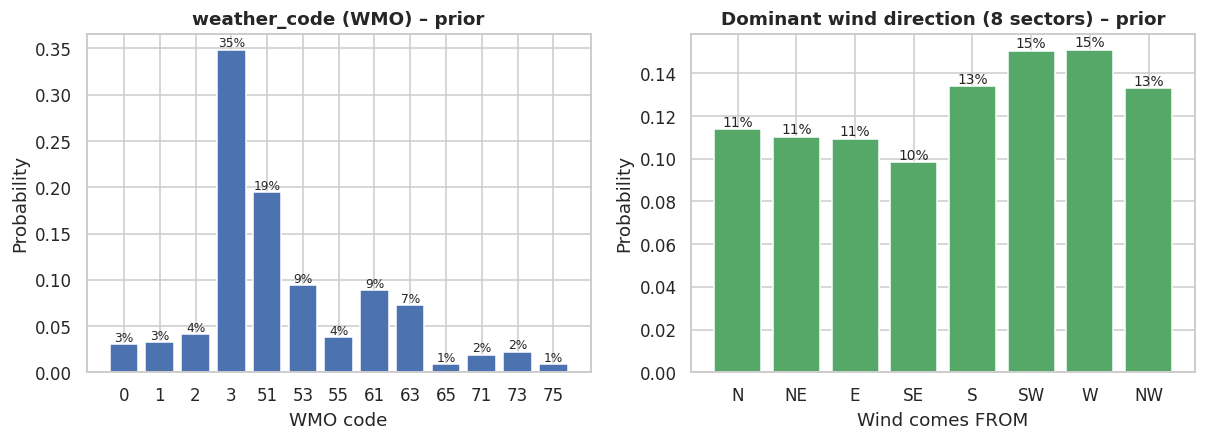

In [8]:
eda["wc_group"] = eda["weather_code"].map(pp.WMO_GROUP)
sectors = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
eda["wind_sector"] = pd.cut((eda["wind_direction_10m_dominant"] + 22.5) % 360,
                            bins=np.arange(0, 361, 45), labels=sectors, right=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
wc = eda["weather_code"].value_counts(normalize=True).sort_index()
b = ax[0].bar(wc.index.astype(str), wc.values, color="#4c72b0")
ax[0].bar_label(b, labels=[f"{v:.0%}" for v in wc.values], fontsize=8)
ax[0].set(title="weather_code (WMO) – prior", xlabel="WMO code", ylabel="Probability")
ws = eda["wind_sector"].value_counts(normalize=True).reindex(sectors)
b = ax[1].bar(ws.index, ws.values, color="#55a868")
ax[1].bar_label(b, labels=[f"{v:.0%}" for v in ws.values], fontsize=9)
ax[1].set(title="Dominant wind direction (8 sectors) – prior", xlabel="Wind comes FROM", ylabel="Probability")
save(fig, "03_categorical_priors")

<div dir="rtl">

**מה למדנו:** הקוד השכיח הוא 3 (מעונן) ואחריו 51 (טפטוף קל). ב-ERA5 מופיעים רק קודי עננות/טפטוף/גשם/שלג – אין ערפל, ממטרים או רעמים – הקוד נגזר מהמשקעים. הכיוונים W/SW שכיחים (רוחות מערביות של הקווים הממוזגים). **השלכה:** איחוד הקודים לקבוצות (`wc_group`).

</div>

<div dir="rtl">

### 2.4 האם סט הנתונים מאוזן? האם הוא מייצג את המציאות?
* ראו את השיעורים בגרף 2.3 – יש **חוסר איזון מתון**: רוב הימים אינם גשומים. זה לא חוסר איזון קיצוני, אך מודל "טיפש" שתמיד חוזה 0 כבר יקבל Accuracy גבוה,
  ולכן בחלק ב' נעדיף מדדים כמו F1/Recall למחלקה 1 ו/או `class_weight`.
* השיעור **שונה מאוד בין ערים** – משמע ש-`location` (ועונה) מכיל מידע חשוב.
* **ייצוג המציאות:** הנתונים מכסים 16+ שנים רצופות בכל העונות ובאותו משקל לכל עיר → מייצגים היטב את האקלים של 6 הערים.
  מגבלות: (1) ERA5 הוא אומדן לתא גריד ולא מדידת תחנה; (2) רק 6 ערים, כולן גדולות וממוזגות – המודל לא בהכרח יכליל לאקלים מדברי/טרופי; (3) המבחן העתידי יהיה על תקופה מאוחרת – אם קיימת מגמת אקלים, יתכן drift קל.

</div>

<div dir="rtl">

### 2.5 קשרים "מעניינים" בין מאפיינים
#### (א) מטריצת מתאמים – מי מתאר את אותה תופעה?

</div>

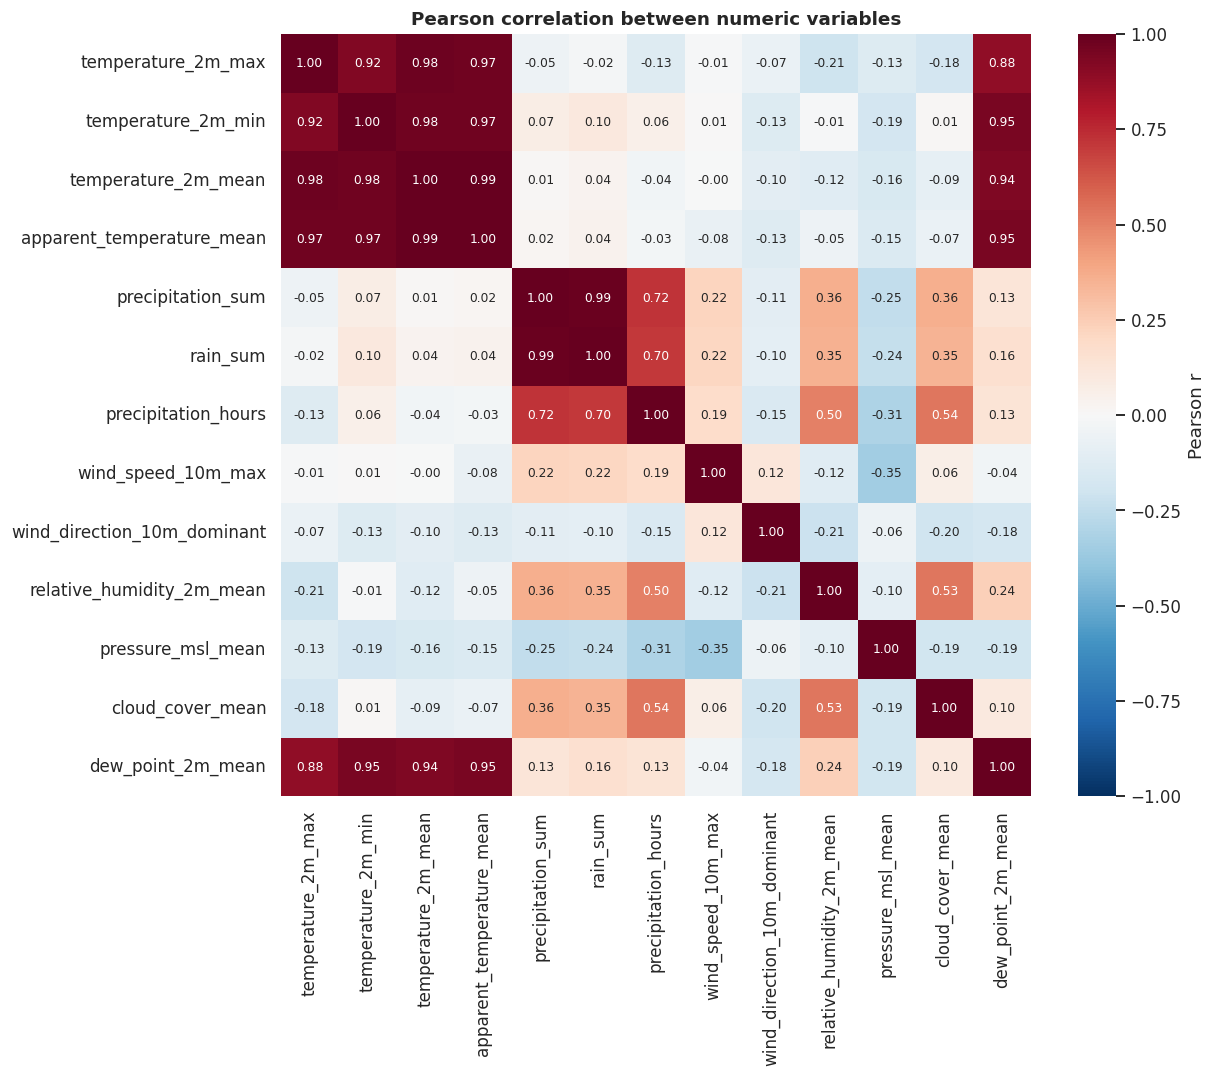

In [9]:
num_cols = [c for c in pp.NUMERIC_REQUIRED + sensing.EXTRA_DAILY if c in eda.columns]
corr = eda[num_cols].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            ax=ax, annot_kws={"size": 8}, cbar_kws={"label": "Pearson r"})
ax.set_title("Pearson correlation between numeric variables")
save(fig, "04_correlation_matrix")

<div dir="rtl">

#### (ב) צפוי: התמדה – גשם היום ↔ גשם מחר

</div>

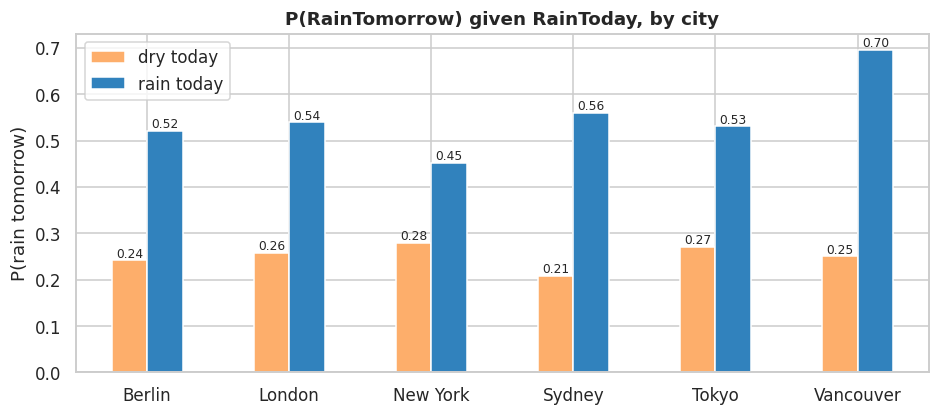

RainTomorrow,0,1
RainToday,,
0,0.748,0.252
1,0.443,0.557


In [10]:
pers = eda.groupby(["location", "RainToday"])[pp.TARGET].mean().unstack().reindex(CITY_ORDER)
pers.columns = ["dry today", "rain today"]
fig, ax = plt.subplots(figsize=(10, 4))
pers.plot.bar(ax=ax, color=["#fdae6b", "#3182bd"], rot=0)
ax.set(title="P(RainTomorrow) given RainToday, by city", ylabel="P(rain tomorrow)", xlabel="")
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8)
save(fig, "05_persistence")
pd.crosstab(eda["RainToday"], eda[pp.TARGET], normalize="index").round(3)

<div dir="rtl">

**מה למדנו (צפוי):** אחרי יום גשום P(גשם מחר) ≈ 56% לעומת ≈ 25% אחרי יום יבש – בכל הערים. מערכות גשם נמשכות יותר מיום. **השלכה:** `rain_today` ומאפייני עבר (`precip_lag1`, `precip_3d`).

</div>

<div dir="rtl">

#### (ג) כיוון הרוח ↔ גשם מחר – קשר שתלוי בגאוגרפיה

</div>

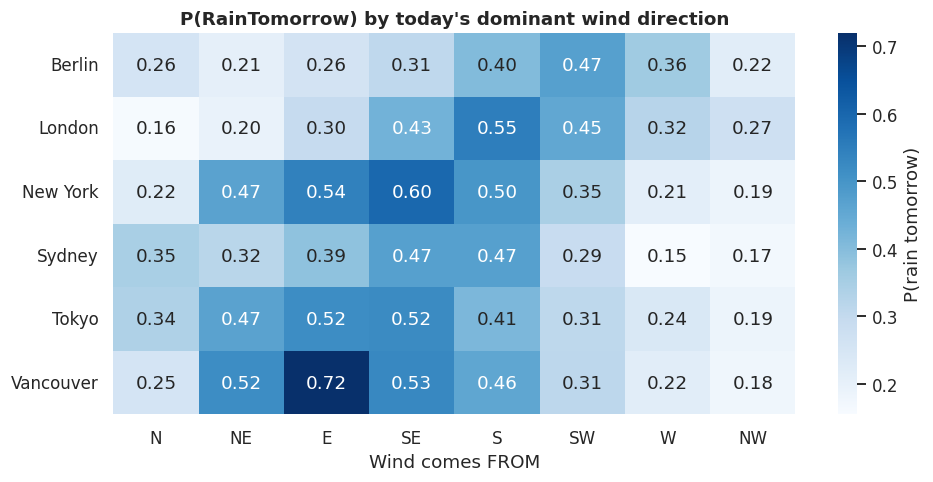

In [11]:
rose = eda.groupby(["location", "wind_sector"], observed=True)[pp.TARGET].mean().unstack().reindex(CITY_ORDER)[sectors]
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(rose, annot=True, fmt=".2f", cmap="Blues", ax=ax, cbar_kws={"label": "P(rain tomorrow)"})
ax.set(title="P(RainTomorrow) by today's dominant wind direction", xlabel="Wind comes FROM", ylabel="")
save(fig, "06_wind_direction_rain")

<div dir="rtl">

**מה למדנו (לא צפוי):** מתאם גולמי של הכיוון עם המטרה כמעט אפסי, אבל **בתוך כל עיר** ההבדלים עצומים: New York SE ≈ 60% מול NW ≈ 19%, Vancouver E ≈ 72% מול NW ≈ 18%. רוח מהים/לפני שקע מתקרב → גשם; רוח מהיבשה → יובש. **השלכה:** קידוד sin/cos ומודלים שלומדים אינטראקציה עיר×כיוון.

</div>

<div dir="rtl">

#### (ד) עונתיות – החודש הגשום שונה בכל עיר

</div>

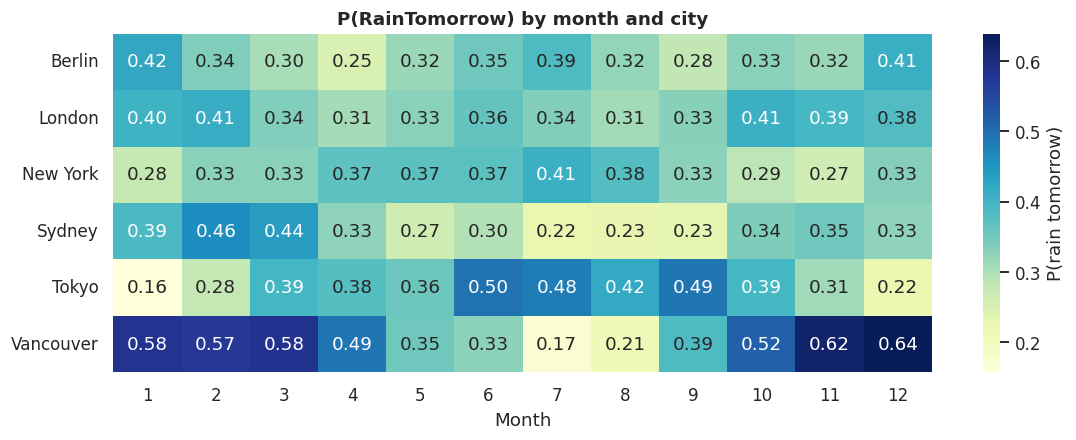

In [12]:
season = eda.groupby(["location", "month"])[pp.TARGET].mean().unstack().reindex(CITY_ORDER)
fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(season, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "P(rain tomorrow)"})
ax.set(title="P(RainTomorrow) by month and city", xlabel="Month", ylabel="")
save(fig, "07_seasonality")

<div dir="rtl">

**מה למדנו:** אין עונה גשומה משותפת – Tokyo שיא ביוני (מונסון, ~50%) ושפל בינואר (~16%); Vancouver שיא בדצמבר (~64%) ושפל ביולי; Sydney בחצי הכדור הדרומי. **השלכה:** עונתיות (`doy_sin/cos`) צריכה לעבוד יחד עם `location`.

</div>

<div dir="rtl">

#### (ה) טמפרטורה מורגשת מול טמפרטורה – ומה מסתתר בהפרש

</div>

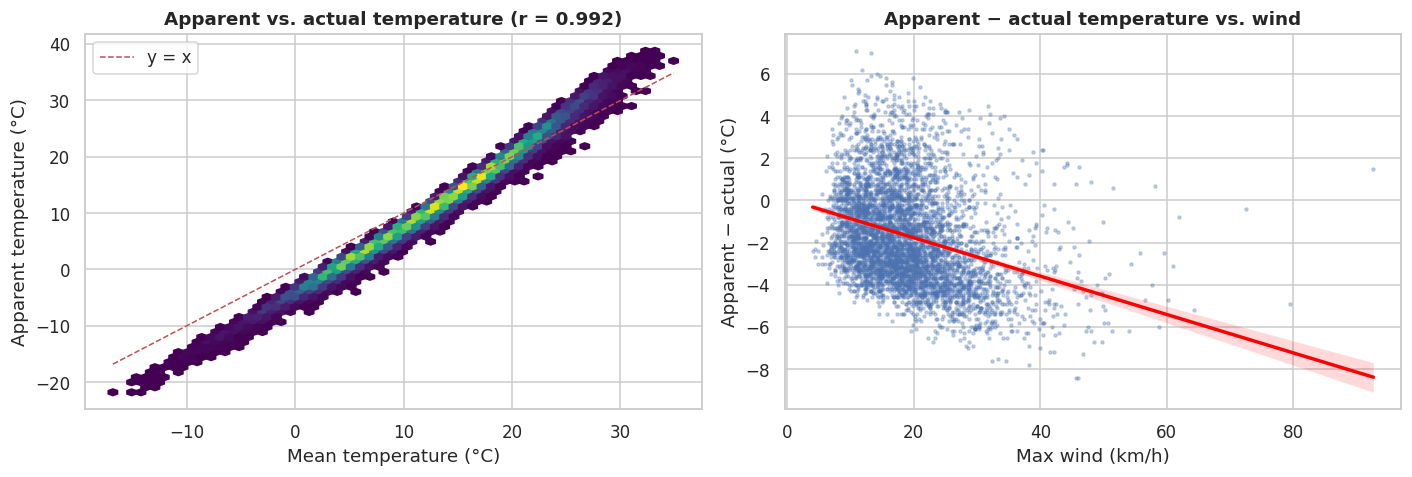

apparent_diff                1.000
wind_speed_10m_max          -0.319
relative_humidity_2m_mean    0.187
dew_point_2m_mean            0.905
Name: apparent_diff, dtype: float64

In [13]:
eda["apparent_diff"] = eda["apparent_temperature_mean"] - eda["temperature_2m_mean"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hexbin(eda["temperature_2m_mean"], eda["apparent_temperature_mean"], gridsize=60, cmap="viridis", mincnt=1)
lim = [eda["temperature_2m_mean"].min(), eda["temperature_2m_mean"].max()]
ax[0].plot(lim, lim, "r--", lw=1, label="y = x")
ax[0].set(title=f"Apparent vs. actual temperature (r = {eda[['temperature_2m_mean','apparent_temperature_mean']].corr().iloc[0,1]:.3f})",
          xlabel="Mean temperature (°C)", ylabel="Apparent temperature (°C)"); ax[0].legend()
if "relative_humidity_2m_mean" in eda:
    sns.regplot(data=eda.sample(5000, random_state=0), x="wind_speed_10m_max", y="apparent_diff",
                scatter_kws={"s": 4, "alpha": 0.3}, line_kws={"color": "red"}, ax=ax[1])
    ax[1].set(title="Apparent − actual temperature vs. wind", xlabel="Max wind (km/h)", ylabel="Apparent − actual (°C)")
fig.tight_layout()
save(fig, "08_apparent_temperature")
cols = ["apparent_diff", "wind_speed_10m_max"] + [c for c in ["relative_humidity_2m_mean", "dew_point_2m_mean"] if c in eda]
eda[cols].corr()["apparent_diff"].round(3)

<div dir="rtl">

**מה למדנו (לא צפוי):** הטמפ' המורגשת כמעט זהה לטמפ' (r≈0.99) – כפילות. אבל ההפרש ביניהן מתואם חזק עם נקודת הטל (r≈0.9) ושלילית עם הרוח – כלומר הוא נושא מידע על **לחות**, שאינה בין 10 משתני החובה. **השלכה:** החלפת `apparent_temperature_mean` ב-`apparent_diff`.

</div>

<div dir="rtl">

### 2.6 מאפיינים שחשודים כמשפיעים על משתנה המטרה – בדיקה
על בסיס ידע מטאורולוגי: משקעים/שעות משקעים היום (התמדה של מערכות), טווח טמפ' יומי קטן (עננות), רוח חזקה (חזיתות),
ומהמשתנים הנוספים – לחות, לחץ נמוך ועננות. נבדוק בעזרת boxplot ומתאם point-biserial מול המטרה.

</div>

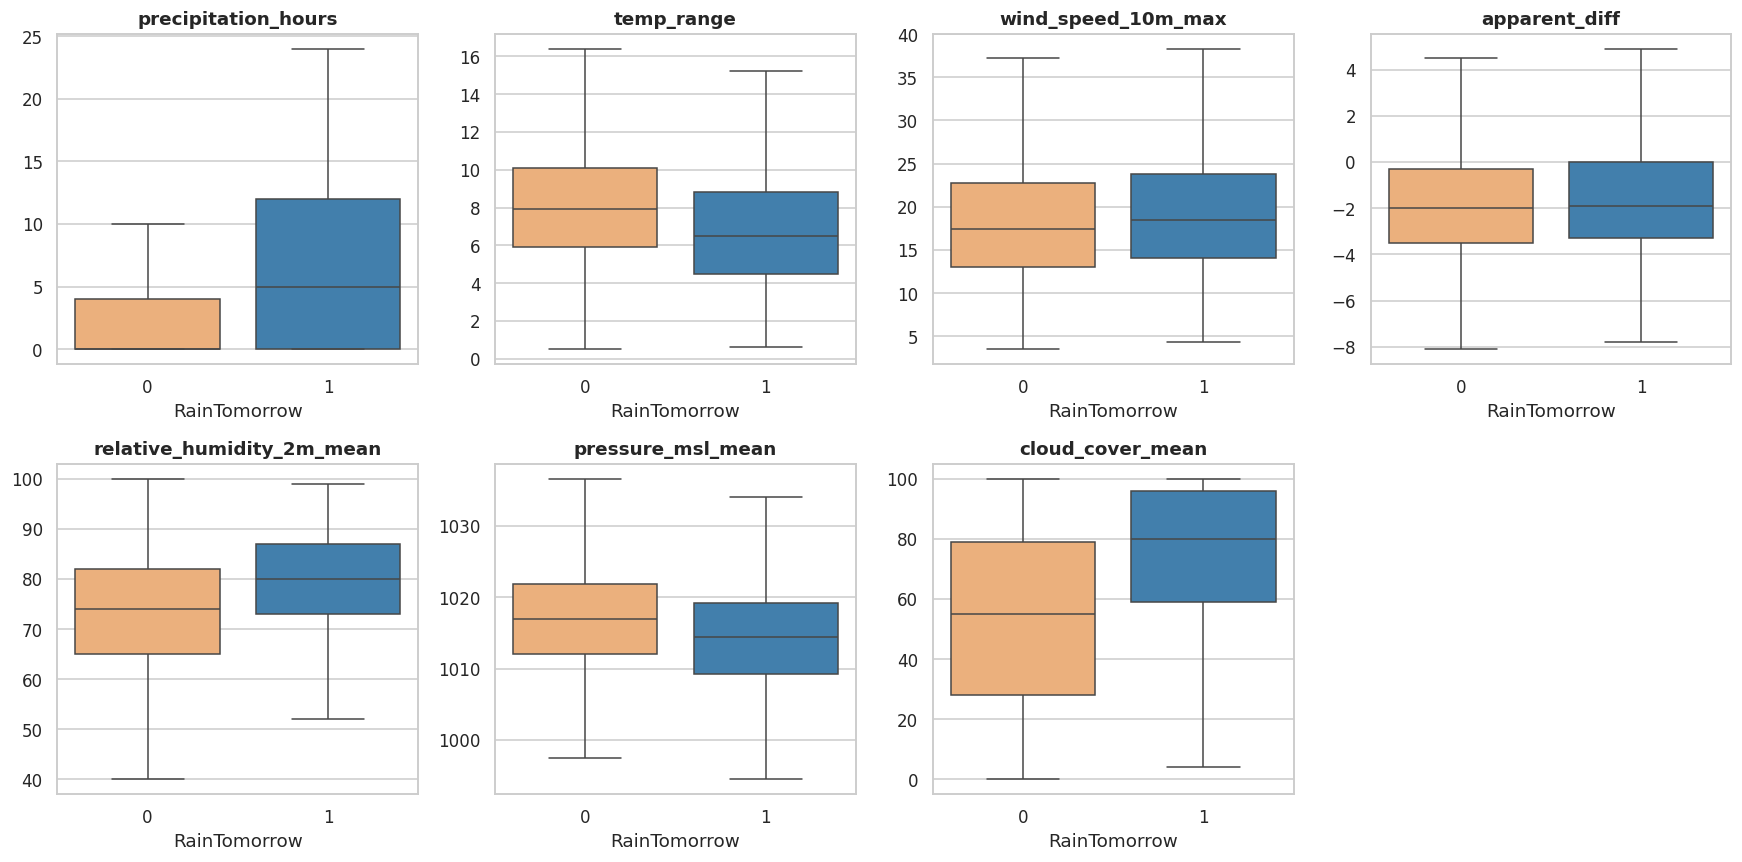

,r with RainTomorrow
cloud_cover_mean,0.336
precipitation_hours,0.333
RainToday,0.306
relative_humidity_2m_mean,0.237
precipitation_sum,0.230
rain_sum,0.225
temp_range,-0.188
pressure_msl_mean,-0.173
wind_direction_10m_dominant,-0.136
dew_point_2m_mean,0.095


In [14]:
eda["temp_range"] = eda["temperature_2m_max"] - eda["temperature_2m_min"]
cand = ["precipitation_hours", "temp_range", "wind_speed_10m_max", "apparent_diff"] + \
       [c for c in ["relative_humidity_2m_mean", "pressure_msl_mean", "cloud_cover_mean"] if c in eda]
fig, axes = plt.subplots(2, (len(cand) + 1) // 2, figsize=(4 * ((len(cand) + 1) // 2), 8))
for ax, c in zip(axes.ravel(), cand):
    sns.boxplot(data=eda, x=pp.TARGET, y=c, ax=ax, showfliers=False, hue=pp.TARGET,
                palette=["#fdae6b", "#3182bd"], legend=False)
    ax.set(title=c, xlabel="RainTomorrow", ylabel="")
for ax in axes.ravel()[len(cand):]: ax.axis("off")
fig.tight_layout()
save(fig, "09_suspected_features")

all_num = [c for c in num_cols] + ["temp_range", "apparent_diff", "RainToday"]
pb = pd.Series({c: stats.pointbiserialr(eda[pp.TARGET], eda[c].fillna(eda[c].median()))[0] for c in all_num})
pb.reindex(pb.abs().sort_values(ascending=False).index).round(3).to_frame("r with RainTomorrow")

<div dir="rtl">

**מה למדנו:** ההשערות אוששו עבור שעות משקעים (המנבא החזק ביותר), גשם היום וטווח טמפ' קטן; מהמשתנים הנוספים – עננות, לחות ולחץ נמוך. הרוח – קשר חלש מהצפוי. הטמפרטורות לבדן כמעט ללא קשר ישיר.

</div>

<div dir="rtl">

### 2.7 משתנים שניתן להסיר על בסיס ידע מוקדם – בדיקת ההשערה
השערות:
1. **`rain_sum`** – כמעט זהה ל-`precipitation_sum` (ההבדל הוא רק שלג) → כפילות.
2. **`apparent_temperature_mean`** – פונקציה של הטמפרטורה (+לחות ורוח) → כפילות גבוהה ל-`temperature_2m_mean`.
3. **`wind_direction_10m_dominant`** – לא מיותר, אבל **בייצוג הגולמי שגוי**: 359° ו-1° קרובים, אך מספרית רחוקים. יוחלף ב-sin/cos.

</div>

In [15]:
r_rain = eda[["precipitation_sum", "rain_sum"]].corr().iloc[0, 1]
diff = (eda["precipitation_sum"] - eda["rain_sum"])
print(f"corr(precipitation_sum, rain_sum) = {r_rain:.4f}")
print(f"days where precipitation != rain (snow involved): {(diff > 0.05).mean():.2%}")
print(diff[diff > 0.05].groupby(eda['location']).size().rename('snow days').to_string())
r_app = eda[["temperature_2m_mean", "apparent_temperature_mean"]].corr().iloc[0, 1]
print(f"\ncorr(temperature_2m_mean, apparent_temperature_mean) = {r_app:.4f}")

corr(precipitation_sum, rain_sum) = 0.9868
days where precipitation != rain (snow involved): 4.79%
location
Berlin       469
London       142
New York     408
Tokyo        145
Vancouver    601

corr(temperature_2m_mean, apparent_temperature_mean) = 0.9924


<div dir="rtl">

**מה למדנו:** ההשערות אוששו – `rain_sum` זהה ל-`precipitation_sum` (r≈0.99) למעט ימי שלג (~5%), ו-`apparent_temperature_mean` כפול לטמפרטורה. **החלטה:** הסרת `rain_sum` (שמירת מידע השלג ב-`snow_water`) והחלפת הטמפ' המורגשת בהפרש.

</div>

<div dir="rtl">

## 3. איכות הנתונים
### 3.1 נתונים חסרים, ימים חסרים בלוח השנה וכפילויות

</div>

In [16]:
missing = sensed.isna().sum().to_frame("missing")
missing["pct"] = (missing["missing"] / len(sensed) * 100).round(3)
print(missing[missing["missing"] > 0] if missing["missing"].any() else "No missing values in any column")

s = sensed.assign(date=pd.to_datetime(sensed["date"]))
gaps = s.groupby("location")["date"].apply(lambda d: int((d.max() - d.min()).days + 1 - d.nunique()))
print("\nmissing calendar days per location:\n", gaps.to_string())
print("\nduplicate (location, date) rows in raw union:",
      sensing.load_raw().query("date >= @sensing.START_DATE").duplicated(["location", "date"]).sum())

No missing values in any column

missing calendar days per location:
 location
Berlin       0
London       0
New York     0
Sydney       0
Tokyo        0
Vancouver    0



duplicate (location, date) rows in raw union: 0


<div dir="rtl">

### 3.2 נתונים שאינם הגיוניים – בדיקות בקוד

</div>

In [17]:
qr = pp.quality_report(sensed.assign(date=pd.to_datetime(sensed["date"])))
qr

,rule,rows
0,min_temp > max_temp,0
1,"mean_temp outside [min,max]",1
2,"temperature outside [-60,60]",0
3,"apparent temp outside [-80,70]",0
4,precipitation < 0,0
5,rain < 0,0
6,rain > precipitation,0
7,"precip_hours outside [0,24]",0
8,"wind speed outside [0,250]",0
9,"wind dir outside [0,360]",0


In [18]:
# Softer consistency checks (possible, but suspicious)
chk = pd.Series({
    "precip > 0 but precip_hours = 0": ((sensed.precipitation_sum > 0) & (sensed.precipitation_hours == 0)).sum(),
    "precip_hours > 0 but precip = 0": ((sensed.precipitation_hours > 0) & (sensed.precipitation_sum == 0)).sum(),
    "rainy weather_code (>=51) but precip < 0.1": ((sensed.weather_code >= 51) & (sensed.precipitation_sum < 0.1)).sum(),
    "dry weather_code (<=3) but precip >= 1": ((sensed.weather_code <= 3) & (sensed.precipitation_sum >= 1)).sum(),
    "days with 0 < precip < 1 mm ('drizzle')": ((sensed.precipitation_sum > 0) & (sensed.precipitation_sum < 1)).sum(),
})
z = np.abs(stats.zscore(sensed[pp.NUMERIC_REQUIRED].drop(columns=["wind_direction_10m_dominant"]), nan_policy="omit"))
chk["|z| > 5 in any numeric column (extreme)"] = int((z > 5).any(axis=1).sum())
chk.to_frame("rows")

,rows
precip > 0 but precip_hours = 0,0
precip_hours > 0 but precip = 0,0
rainy weather_code (>=51) but precip < 0.1,70
dry weather_code (<=3) but precip >= 1,0
days with 0 < precip < 1 mm ('drizzle'),6743
|z| > 5 in any numeric column (extreme),305


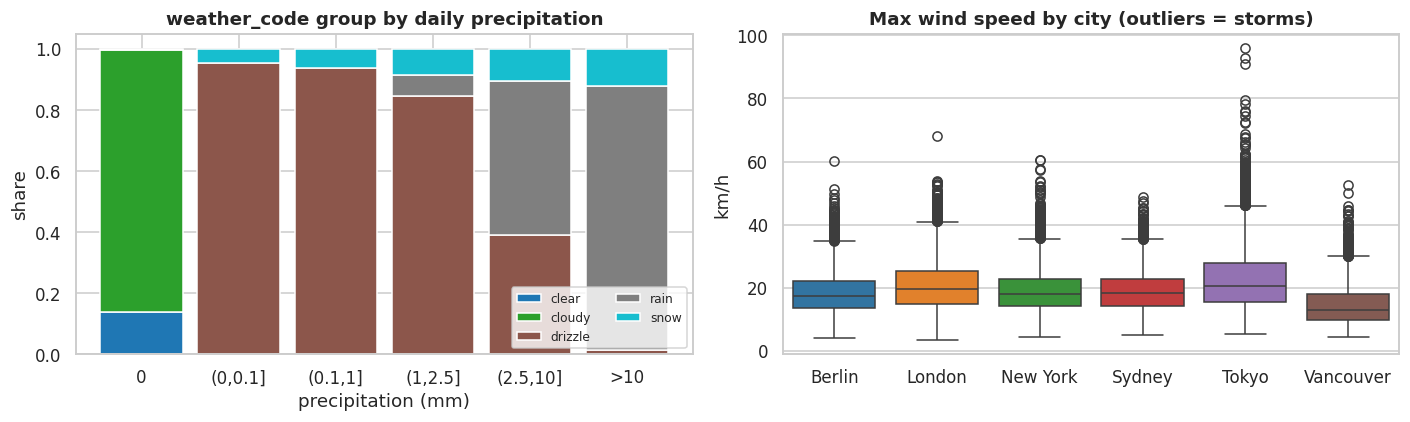

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ct = pd.crosstab(pd.cut(sensed["precipitation_sum"], [-0.01, 0, 0.1, 1, 2.5, 10, 1000],
                        labels=["0", "(0,0.1]", "(0.1,1]", "(1,2.5]", "(2.5,10]", ">10"]),
                 sensed["weather_code"].map(pp.WMO_GROUP), normalize="index")
ct.plot.bar(stacked=True, ax=ax[0], colormap="tab10", rot=0, width=0.85)
ax[0].set(title="weather_code group by daily precipitation", xlabel="precipitation (mm)", ylabel="share")
ax[0].legend(fontsize=8, ncol=2)
sns.boxplot(data=sensed, x="location", y="wind_speed_10m_max", order=CITY_ORDER, ax=ax[1],
            hue="location", palette=PALETTE, legend=False)
ax[1].set(title="Max wind speed by city (outliers = storms)", xlabel="", ylabel="km/h")
fig.tight_layout()
save(fig, "10_quality_checks")

<div dir="rtl">

**מה למדנו:** אין חוסרים, אין ימים חסרים ואין כפילויות (reanalysis מספק שדה מלא). נמצאה הפרה אחת בלבד (ממוצע מחוץ ל-[min,max] ב-London, 2016-12-31 – יום אחרון של בקשה שנתית, כנראה ארטיפקט אגרגציה) → תוחלף ב-NaN ותושלם. ערכי קיצון (|z|>5) הם סערות אמיתיות ולכן נשמרים. ~18% מהימים עם 0<משקעים<1 מ"מ – הטיית "טפטוף" של ERA5 שסף ה-1 מ"מ מנטרל.

</div>

<div dir="rtl">

## 4. הכנת הנתונים
כל השלבים ממומשים ב-`preprocessing.py` (כדי שאותו קוד בדיוק ירוץ על סט המבחן בחלק ב'). כאן נריץ ונבדוק כל שלב.

| שלב | מה עשינו | למה |
|---|---|---|
| ניקוי | ערך בלתי אפשרי (כללי 3.2) → NaN | לא "לנחש" ערך שגוי; להשלים אותו כמו חוסר |
| לוח שנה מלא | כל עיר → סדרה יומית רציפה | כדי ש"מחר" ו"אתמול" יהיו באמת היום הסמוך |
| מטרה | `RainTomorrow` מ-`precipitation_sum` **הגולמי** של מחר; הסרת היום האחרון | ללא דליפת מידע וללא מטרה "מושלמת" |
| השלמה | אינטרפולציה בזמן (עד 3 ימים) בתוך כל עיר, גיבוי: חציון עיר×חודש | מזג אוויר רציף בזמן ותלוי עונה/מקום – השלמה "חכמה" ע"ס עמודה אחרת (זמן) |
| השמטה | `rain_sum`, `apparent_temperature_mean`, `wind_direction` גולמי, `weather_code` גולמי | כפילויות / ייצוג לא מתאים (2.7) – מוחלפים במאפיינים נגזרים |
| משתנים נוספים | לא נכנסים ל-final | ייתכן שלא יופיעו ב-JSON של סט המבחן |

</div>

In [20]:
final = pp.prepare(sensed)
PROC_DIR.mkdir(parents=True, exist_ok=True)
final.to_csv(PROC_DIR / "final_dataset.csv", index=False)
print(final.shape)
print("missing values left:", int(final.isna().sum().sum()))
print("rows removed (last day per city + days without a valid tomorrow):", len(sensed) - len(final))
final.head()

(36882, 22)
missing values left: 0
rows removed (last day per city + days without a valid tomorrow): 6


,location,date,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,precipitation_hours,wind_speed_10m_max,temp_range,apparent_diff,wind_dir_sin,wind_dir_cos,doy_sin,doy_cos,rain_today,snow_water,precip_intensity,precip_lag1,precip_3d,temp_mean_diff1,wc_group,RainTomorrow
0,Berlin,2010-01-01,-1.6,-3.2,-2.5,3.2,12.0,16.3,1.6,-4.7,0.694658,0.719340,0.017202,0.999852,1,3.2,2,3.2,3.2,0.0,snow,1
1,Berlin,2010-01-02,-1.2,-5.7,-3.2,1.1,9.0,15.8,4.5,-4.4,-0.587785,0.809017,0.034398,0.999408,1,1.1,1,3.2,4.3,-0.7,snow,0
2,Berlin,2010-01-03,-4.9,-8.9,-6.7,0.0,0.0,7.3,4.0,-3.8,0.754710,0.656059,0.051584,0.998669,0,0.0,0,1.1,4.3,-3.5,snow,0
3,Berlin,2010-01-04,-6.3,-9.6,-7.6,0.0,0.0,13.0,3.3,-4.4,-0.573576,-0.819152,0.068755,0.997634,0,0.0,0,0.0,1.1,-0.9,cloudy,0
4,Berlin,2010-01-05,-5.4,-11.7,-7.7,0.0,0.0,11.2,6.3,-4.6,0.069756,-0.997564,0.085906,0.996303,0,0.0,0,0.0,0.0,-0.1,cloudy,0


<div dir="rtl">

### 4.1 דיסקרטיזציה
* **`precip_intensity`** – `precipitation_sum` מוטה מאוד ואפס-מנופח (סעיף 2.3). חילקנו לפי ספי עוצמה מטאורולוגיים מקובלים:
  0 = יבש (<0.1), 1 = קל (0.1–2.5), 2 = בינוני (2.5–10), 3 = חזק (≥10). הקידוד **מספרי-סדור** (0<1<2<3) כדי לשמר את הסדר.
  את הערך הרציף השארנו – בחלק ב' נבדוק איזה ייצוג עדיף לכל מודל (למשל Naive Bayes ייהנה מהבדיד).
* **`wc_group`** – איחוד 28 קודי WMO ל-7 קבוצות משמעותיות (clear, cloudy, fog, drizzle, rain, snow, thunder) – מקטין ממדיות ומאחד קטגוריות בעלות השפעה דומה.
* **`rain_today`** – סף 1.0 מ"מ (אותו סף של המטרה).
* לא ביצענו דיסקרטיזציה לטמפרטורות/רוח – הקשר שלהן למטרה רציף והדרגתי (2.6), וחלוקה לתאים הייתה מאבדת מידע.

</div>

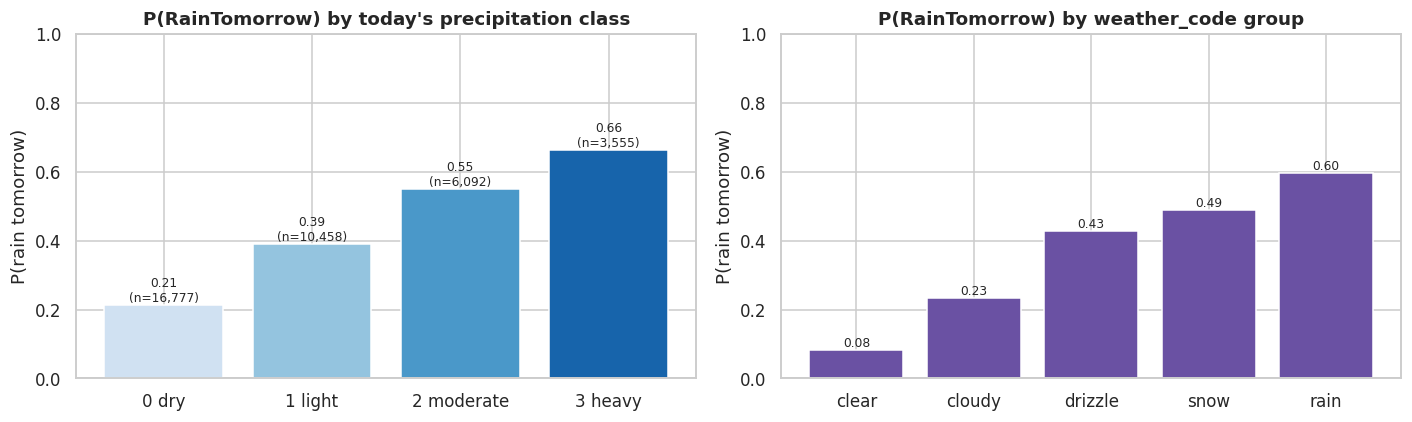

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
pi = final.groupby("precip_intensity")[pp.TARGET].agg(["mean", "size"])
b = ax[0].bar(["0 dry", "1 light", "2 moderate", "3 heavy"], pi["mean"], color=sns.color_palette("Blues", 4))
ax[0].bar_label(b, labels=[f"{m:.2f}\n(n={n:,})" for m, n in zip(pi["mean"], pi["size"])], fontsize=8)
ax[0].set(title="P(RainTomorrow) by today's precipitation class", ylabel="P(rain tomorrow)", ylim=(0, 1))
wg = final.groupby("wc_group")[pp.TARGET].agg(["mean", "size"]).sort_values("mean")
b = ax[1].bar(wg.index, wg["mean"], color="#6a51a3")
ax[1].bar_label(b, labels=[f"{m:.2f}" for m in wg["mean"]], fontsize=8)
ax[1].set(title="P(RainTomorrow) by weather_code group", ylabel="P(rain tomorrow)", ylim=(0, 1))
fig.tight_layout()
save(fig, "11_discretization")

<div dir="rtl">

**מה למדנו:** P(גשם מחר) עולה באופן מונוטוני עם קטגוריית העוצמה (≈21% → 39% → 55% → 66%) – הסדר נשמר ולכן הקידוד הסדור מוצדק. גם קבוצות ה-weather_code מסודרות בבירור (clear ≈ 8% … rain ≈ 60%).

</div>

<div dir="rtl">

### 4.2 גזירת מאפיינים חדשים
| מאפיין | נוסחה | היגיון |
|---|---|---|
| `temp_range` | max − min | יום מעונן/לח → טווח קטן |
| `apparent_diff` | apparent − mean | מסיר את הכפילות עם הטמפ' ומשאיר את "תוספת" הלחות/רוח |
| `wind_dir_sin/cos` | sin/cos של הכיוון | ייצוג מעגלי נכון |
| `doy_sin/cos` | sin/cos של יום בשנה | עונתיות רציפה (דצמבר קרוב לינואר) |
| `snow_water` | precipitation − rain | שומר את מידע השלג אחרי השמטת `rain_sum` |
| `precip_lag1`, `precip_3d` | משקעים אתמול / 3 ימים אחרונים | מערכות גשם נמשכות כמה ימים |
| `temp_mean_diff1` | טמפ' היום − אתמול | ירידת טמפ' חדה = מעבר חזית |

כולם משתמשים **רק בהיום ובעבר** – אין דליפה מהיום הבא.

</div>

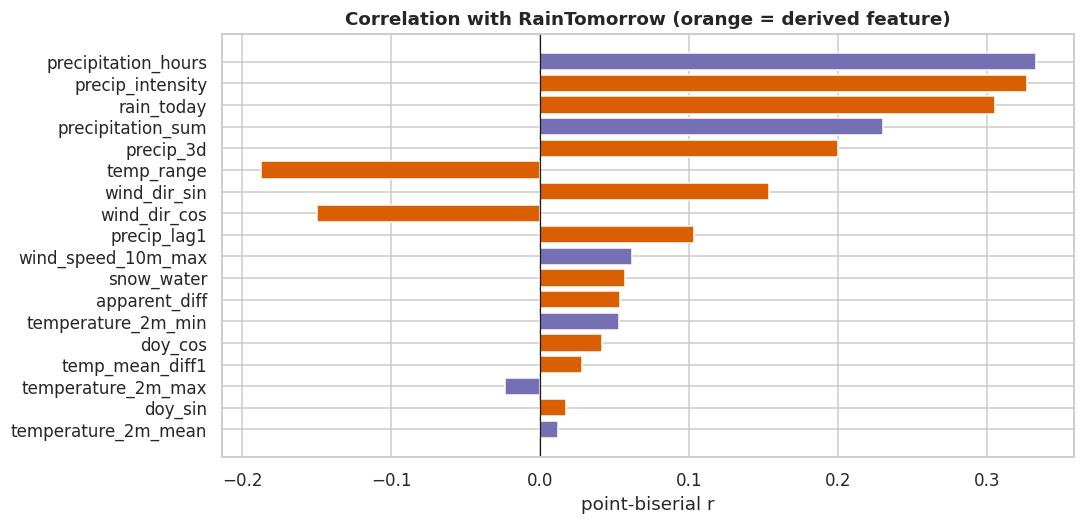

,r
precipitation_hours,0.333
precip_intensity,0.327
rain_today,0.306
precipitation_sum,0.230
precip_3d,0.200
temp_range,-0.188
wind_dir_sin,0.154
wind_dir_cos,-0.150
precip_lag1,0.103
wind_speed_10m_max,0.062


In [22]:
new_feats = ["temp_range", "apparent_diff", "wind_dir_sin", "wind_dir_cos", "doy_sin", "doy_cos",
             "snow_water", "precip_lag1", "precip_3d", "temp_mean_diff1", "rain_today", "precip_intensity"]
orig = ["temperature_2m_max", "temperature_2m_min", "temperature_2m_mean", "precipitation_sum",
        "precipitation_hours", "wind_speed_10m_max"]
r = pd.Series({c: stats.pointbiserialr(final[pp.TARGET], final[c])[0] for c in orig + new_feats})
fig, ax = plt.subplots(figsize=(10, 5))
order = r.abs().sort_values().index
ax.barh(order, r[order], color=["#d95f02" if c in new_feats else "#7570b3" for c in order])
ax.axvline(0, c="k", lw=0.8)
ax.set(title="Correlation with RainTomorrow (orange = derived feature)", xlabel="point-biserial r")
save(fig, "12_feature_target_corr")
r.round(3).sort_values(key=abs, ascending=False).to_frame("r")

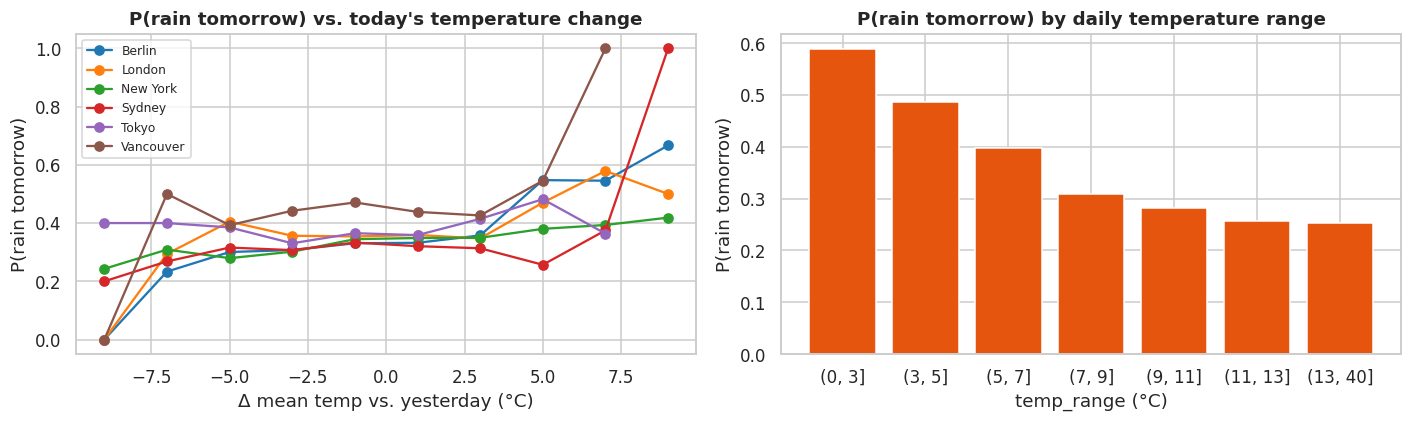

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for loc in CITY_ORDER:
    d = final[final.location == loc]
    m = d.groupby(pd.cut(d["temp_mean_diff1"], np.arange(-10, 10.1, 2)), observed=True)[pp.TARGET].mean()
    ax[0].plot([i.mid for i in m.index], m.values, marker="o", label=loc, color=PALETTE[loc])
ax[0].set(title="P(rain tomorrow) vs. today's temperature change", xlabel="Δ mean temp vs. yesterday (°C)", ylabel="P(rain tomorrow)")
ax[0].legend(fontsize=8)
m = final.groupby(pd.cut(final["temp_range"], [0, 3, 5, 7, 9, 11, 13, 40]), observed=True)[pp.TARGET].mean()
ax[1].bar([str(i) for i in m.index], m.values, color="#e6550d")
ax[1].set(title="P(rain tomorrow) by daily temperature range", xlabel="temp_range (°C)", ylabel="P(rain tomorrow)")
fig.tight_layout()
save(fig, "13_derived_features")

<div dir="rtl">

**מה למדנו:** טווח טמפ' יומי קטן (≤3°C) → ~59% גשם מחר, לעומת ~25% בטווח גדול – המאפיין הנגזר `temp_range` הוא מהחזקים. `precip_intensity`, `rain_today` ו-`precip_3d` מתואמים עם המטרה יותר מרוב המשתנים המקוריים.

</div>

<div dir="rtl">

### 4.3 סיכום סט הנתונים הסופי

</div>

In [24]:
print(final.dtypes.value_counts().to_string())
print("\nfeatures:", len(pp.FEATURES), pp.FEATURES)
final.describe().T.round(2)

float64           16
int64              3
object             2
datetime64[ns]     1

features: 19 ['temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'precipitation_sum', 'precipitation_hours', 'wind_speed_10m_max', 'temp_range', 'apparent_diff', 'wind_dir_sin', 'wind_dir_cos', 'doy_sin', 'doy_cos', 'rain_today', 'snow_water', 'precip_intensity', 'precip_lag1', 'precip_3d', 'temp_mean_diff1', 'wc_group']


,count,mean,min,25%,50%,75%,max,std
date,36882,2018-06-01 00:00:00,2010-01-01 00:00:00,2014-03-17 00:00:00,2018-06-01 00:00:00,2022-08-16 00:00:00,2026-10-30 00:00:00,NaN
temperature_2m_max,36882.0,16.87056,-12.7,10.5,17.3,22.9,42.0,8.259353
temperature_2m_min,36882.0,9.210515,-20.6,3.6,9.5,14.8,29.6,7.598294
temperature_2m_mean,36882.0,12.994547,-16.8,7.0,13.3,18.8,34.9,7.728569
precipitation_sum,36882.0,3.188677,0.0,0.0,0.2,2.7,183.6,7.689109
precipitation_hours,36882.0,4.30763,0.0,0.0,1.0,7.0,24.0,6.002647
wind_speed_10m_max,36882.0,19.06854,3.5,13.4,17.8,23.2,95.9,7.892612
temp_range,36882.0,7.660046,0.5,5.3,7.4,9.7,26.2,3.181316
apparent_diff,36882.0,-1.700068,-9.4,-3.4,-2.0,-0.3,7.1,2.336501
wind_dir_sin,36882.0,-0.101879,-1.0,-0.798636,-0.224951,0.601815,1.0,0.705663


<div dir="rtl">

## 5. מה למדנו? (סיכום)
ראו את הסיכום המלא בדו"ח. עיקרי הדברים: חוסר איזון מתון ושונה בין ערים, התמדה חזקה של גשם, תלות של משמעות כיוון הרוח בגאוגרפיה,
עונתיות שונה בכל עיר, כפילויות ברורות שהוסרו, ונתונים נקיים כמעט לחלוטין (ERA5). בחלק ב' – פיצול **לפי זמן** (train על השנים המוקדמות, validation על המאוחרות)
כדי לדמות את סט המבחן העתידי.

</div>